# Thực nghiệm mô hình nâng thêm trên Criteo v2.1 — Google Colab T4, 2 triệu mẫu huấn luyện

Sổ tay này là phiên bản Google Colab của quy trình thực nghiệm hiện tại. Biến kết quả là conversion, biến can thiệp là treatment, đặc trưng đầu vào là f0–f11. Tập huấn luyện dùng 2.000.000 quan sát lấy mẫu phân tầng; tập xác thực dùng 200.000 quan sát và tập kiểm tra được giữ toàn bộ.


In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# Chỉ chạy khi Runtime đang là T4 GPU và Internet đã bật.
!nvidia-smi
!nvcc --version
!python3 -m pip -q install -U pip "setuptools<82" wheel scikit-build-core build "ninja>=1.11" "jedi>=0.16"
!python3 -m pip -q install "numpy>=2.0" "pandas>=2.2" pyarrow joblib seaborn scikit-learn matplotlib "causalml==0.17.0"
!python3 -m pip -q uninstall -y lightgbm
!rm -rf /content/LightGBM
!git clone --recursive --depth 1 --branch v4.7.0 https://github.com/lightgbm-org/LightGBM.git /content/LightGBM
%cd /content/LightGBM
!sh ./build-python.sh install --cuda --no-isolation
%cd /content

# Dừng nếu LightGBM không truy cập được GPU; không âm thầm chạy lại bằng CPU.
import numpy as np
from lightgbm import LGBMClassifier
x_smoke = np.random.default_rng(42).normal(size=(1000, 12)).astype("float32")
y_smoke = (x_smoke[:, 0] + x_smoke[:, 1] > 0).astype("int8")
smoke = LGBMClassifier(n_estimators=5, learning_rate=0.1, max_bin=63, device_type="cuda", random_state=42, verbosity=-1)
smoke.fit(x_smoke, y_smoke)
print("CUDA LightGBM smoke test: đạt yêu cầu")


Wed Sep 30 13:18:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Cấu hình và khả năng tái lập

Mọi phép chia, lấy mẫu, mô hình và chiến lược ngẫu nhiên dùng hạt giống cố định. Chế độ `laptop` ưu tiên hoàn tất trong tài nguyên hữu hạn; các giới hạn thực tế được ghi vào đầu ra.

In [3]:
from pathlib import Path
from datetime import datetime, timezone
import os, sys, json, gc, time, hashlib, warnings, subprocess, importlib, importlib.metadata as metadata

RUN_MODE = "colab_t4_full"
RANDOM_STATE = 42
TIE_BREAK_SEED = 42
N_JOBS = -1
CHUNK_SIZE = 500_000

# Không giới hạn số quan sát ở bất kỳ tập nào.
TRAIN_MAX = None
VALID_MAX = None
TEST_MAX = None
CF_TRAIN_MAX = 200_000
CF_N_JOBS = -1  # Tăng lên -1 để sử dụng toàn bộ số luồng CPU khả dụng

TARGET_RATES = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.75, 1.00]
RANDOM_REPEATS = 30
BOOTSTRAP_REPEATS = 1_000
CI_TARGET_RATES = [0.10, 0.20, 0.50]
PIPELINE_VERSION = "2026-09-30-full-consistent-v2"

# Giữ nguyên nơi chứa dữ liệu; lưu kết quả full riêng để không ghi đè kết quả 2 triệu mẫu.
ROOT = Path("/content/drive/MyDrive/uplift_modelling_colab_2m")
OUT = ROOT / "outputs_full_consistent_v2"
TABLES, FIGURES, MODELS = OUT / "tables", OUT / "figures", OUT / "models"

ROOT.mkdir(parents=True, exist_ok=True)
for p in (OUT, TABLES, FIGURES, MODELS):
    p.mkdir(parents=True, exist_ok=True)

RUN_STARTED = datetime.now(timezone.utc)
warnings_log = []

print({
    "RUN_MODE": RUN_MODE,
    "RANDOM_STATE": RANDOM_STATE,
    "TIE_BREAK_SEED": TIE_BREAK_SEED,
    "N_JOBS": N_JOBS,
    "train_max": TRAIN_MAX,
    "validation_max": VALID_MAX,
    "test_max": TEST_MAX,
    "bootstrap_repeats": BOOTSTRAP_REPEATS,
    "root": str(ROOT),
    "output": str(OUT)
})

{'RUN_MODE': 'colab_t4_full', 'RANDOM_STATE': 42, 'TIE_BREAK_SEED': 42, 'N_JOBS': -1, 'train_max': None, 'validation_max': None, 'test_max': None, 'bootstrap_repeats': 1000, 'root': '/content/drive/MyDrive/uplift_modelling_colab_2m', 'output': '/content/drive/MyDrive/uplift_modelling_colab_2m/outputs_full_consistent_v2'}


## 3. Kiểm tra môi trường

In Python/kernel và phiên bản thư viện. Nếu thiếu, lệnh cài đặt dùng chính `sys.executable` của kernel. API của Causal Forest và LightGBM được kiểm tra trực tiếp.

In [4]:
required = {"pandas":"pandas", "numpy":"numpy", "scikit-learn":"sklearn", "lightgbm":"lightgbm", "causalml":"causalml", "matplotlib":"matplotlib", "seaborn":"seaborn", "pyarrow":"pyarrow", "joblib":"joblib"}
missing = [pkg for pkg, mod in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Cài thư viện thiếu bằng Python của kernel:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, inspect
from sklearn.model_selection import train_test_split
from lightgbm import LGBMClassifier, LGBMRegressor, early_stopping, log_evaluation
from causalml.inference.tree import CausalRandomForestRegressor

versions = []
for pkg in required:
    try: ver = metadata.version(pkg)
    except metadata.PackageNotFoundError: ver = "unknown"
    versions.append({"package": pkg, "version": ver})
env_df = pd.DataFrame(versions)
env_df.to_csv(TABLES / "environment_versions.csv", index=False)
print("Python:", sys.version)
print("Kernel executable:", sys.executable)
display(env_df)
print("CausalRandomForestRegressor:", inspect.signature(CausalRandomForestRegressor))
print("CRF.fit:", inspect.signature(CausalRandomForestRegressor.fit))
print("CRF.predict:", inspect.signature(CausalRandomForestRegressor.predict))

ERROR:duecredit:Failed to import duecredit due to No module named 'duecredit'


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Kernel executable: /usr/bin/python3


,package,version
0,pandas,2.2.3
1,numpy,2.1.3
2,scikit-learn,1.6.1
3,lightgbm,4.7.0
4,causalml,0.17.0
5,matplotlib,3.10.0
6,seaborn,0.13.2
7,pyarrow,23.0.1
8,joblib,1.6.0


CausalRandomForestRegressor: (n_estimators: int = 100, *, control_name: Union[int, str] = 0, criterion: str = 'causal_mse', alpha: float = 0.05, max_depth: int = None, min_samples_split: int = 60, min_samples_leaf: int = 100, min_group_samples: int = 50, min_weight_fraction_leaf: float = 0.0, max_features: Union[int, float, str] = 1.0, max_leaf_nodes: int = None, min_impurity_decrease: float = -inf, bootstrap: bool = True, oob_score: bool = False, n_jobs: int = None, random_state: int = None, verbose: int = 0, warm_start: bool = False, ccp_alpha: float = 0.0, groups_penalty: float = 0.5, max_samples: int = None, groups_cnt: bool = True, groups_cnt_mode: str = 'nodes')
CRF.fit: (self, X: numpy.ndarray, treatment: numpy.ndarray, y: numpy.ndarray, sample_weight: numpy.ndarray = None)
CRF.predict: (self, X: numpy.ndarray, with_outcomes: bool = False) -> numpy.ndarray


## 4. Đọc và kiểm tra dữ liệu

Tự tìm tệp Criteo hiện có, chỉ đọc các cột cần thiết theo lô và ép kiểu tiết kiệm bộ nhớ. Việc chia/lấy mẫu diễn ra trong cùng lượt đọc để tránh giữ toàn bộ 3,25 GB trong RAM.

In [5]:
FEATURES = [f"f{i}" for i in range(12)]
USECOLS = FEATURES + ["treatment", "conversion"]

candidates = (
    list(ROOT.rglob("criteo-research-uplift-v2.1.csv.gz"))
    + list(ROOT.rglob("criteo-uplift-v2.1.csv"))
    + list(ROOT.rglob("*uplift*v2*.csv.gz"))
)
if not candidates:
    candidates = list(ROOT.rglob("*uplift*v2*.csv"))
if not candidates:
    raise FileNotFoundError("Không tìm thấy dữ liệu Criteo Uplift v2 trong dự án.")

DATA_PATH = candidates[0]
print("Dữ liệu:", DATA_PATH, f"({DATA_PATH.stat().st_size / 1e9:.2f} GB)")

# Bộ sinh số ngẫu nhiên riêng cho từng tầng treatment_conversion.
# Dữ liệu được chia 70% huấn luyện, 15% kiểm định, 15% kiểm tra
# trong từng tầng để duy trì cơ cấu treatment và conversion.
split_rng = {s: np.random.default_rng(RANDOM_STATE + 100 + s) for s in range(4)}
keep_rng = np.random.default_rng(RANDOM_STATE + 500)

parts = {"train": [], "validation": [], "test": []}
agg = {
    name: {"n": 0, "treated": 0, "y": 0, "ty": 0, "cy": 0}
    for name in parts
}
global_agg = {"n": 0, "treated": 0, "y": 0, "missing": 0}
unique_t, unique_y = set(), set()
row_offset = 0

# Giữ toàn bộ quan sát của cả ba tập sau khi phân chia.
train_candidate_prob = 1.0
valid_candidate_prob = 1.0
test_candidate_prob = 1.0

for chunk in pd.read_csv(DATA_PATH, usecols=USECOLS, chunksize=CHUNK_SIZE):
    chunk[FEATURES] = chunk[FEATURES].astype("float32")
    chunk[["treatment", "conversion"]] = chunk[["treatment", "conversion"]].astype("int8")

    n = len(chunk)
    global_agg["n"] += n
    global_agg["treated"] += int(chunk.treatment.sum())
    global_agg["y"] += int(chunk.conversion.sum())
    global_agg["missing"] += int(chunk.isna().sum().sum())

    unique_t.update(chunk.treatment.unique().tolist())
    unique_y.update(chunk.conversion.unique().tolist())

    strata = 2 * chunk.treatment.to_numpy(np.int8) + chunk.conversion.to_numpy(np.int8)

    u = np.empty(n, dtype="float32")
    for s in range(4):
        mask = strata == s
        u[mask] = split_rng[s].random(mask.sum(), dtype=np.float32)

    split_masks = {
        "train": u < 0.70,
        "validation": (u >= 0.70) & (u < 0.85),
        "test": u >= 0.85
    }

    probs = {
        "train": train_candidate_prob,
        "validation": valid_candidate_prob,
        "test": test_candidate_prob
    }

    ids = np.arange(row_offset, row_offset + n, dtype=np.int64)

    for name, sm in split_masks.items():
        sub = chunk.loc[sm]

        a = agg[name]
        a["n"] += len(sub)
        a["treated"] += int(sub.treatment.sum())
        a["y"] += int(sub.conversion.sum())
        a["ty"] += int(sub.loc[sub.treatment.eq(1), "conversion"].sum())
        a["cy"] += int(sub.loc[sub.treatment.eq(0), "conversion"].sum())

        km = sm & (keep_rng.random(n) < probs[name])
        if km.any():
            kept = chunk.loc[km].copy()
            kept.insert(0, "row_id", ids[km])
            parts[name].append(kept)

    row_offset += n

raw_parts = {k: pd.concat(v, ignore_index=True) for k, v in parts.items()}
del parts
gc.collect()

print("Kích thước gốc:", global_agg["n"], "| cột:", USECOLS)
print("Kiểu dữ liệu mẫu:\n", raw_parts["train"].dtypes)
print(
    "Treatment rate:", global_agg["treated"] / global_agg["n"],
    "| conversion rate:", global_agg["y"] / global_agg["n"]
)
print("Missing:", global_agg["missing"], "| unique T/Y:", sorted(unique_t), sorted(unique_y))

if global_agg["missing"] or unique_t != {0, 1} or unique_y != {0, 1}:
    warnings_log.append("Dữ liệu có missing hoặc giá trị nhị phân ngoài {0,1}.")
if not (0.80 < global_agg["treated"] / global_agg["n"] < 0.90):
    warnings_log.append("Tỷ lệ treatment khác đáng kể mô tả 85%.")

Dữ liệu: /content/drive/MyDrive/uplift_modelling_colab_2m/data/criteo-uplift-v2.1.csv (3.25 GB)
Kích thước gốc: 13979592 | cột: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion']
Kiểu dữ liệu mẫu:
 row_id          int64
f0            float32
f1            float32
f2            float32
f3            float32
f4            float32
f5            float32
f6            float32
f7            float32
f8            float32
f9            float32
f10           float32
f11           float32
treatment        int8
conversion       int8
dtype: object
Treatment rate: 0.8500001287591226 | conversion rate: 0.002916680257907384
Missing: 0 | unique T/Y: [0, 1] [0, 1]


## 5. Xác định biến nghiên cứu

`X=f0..f11`, `T=treatment`, `Y=conversion`. `visit`, `exposure`, `conversion` và treatment thực tế không đi vào ma trận đặc trưng khi tạo điểm uplift.

In [6]:
print("X =", FEATURES)
print("T = treatment; Y = conversion")
assert set(USECOLS) == set(FEATURES + ["treatment", "conversion"])

X = ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
T = treatment; Y = conversion


## 6. Chia dữ liệu

Phân bổ ngẫu nhiên 70%/15%/15% độc lập trong từng tầng. Bảng dưới đây dùng thống kê đầy đủ trước khi lấy mẫu huấn luyện/xác thực.

In [7]:
rows=[]
for name,a in agg.items():
    nt, nc = a["treated"], a["n"]-a["treated"]
    rt, rc = a["ty"]/nt, a["cy"]/nc
    rows.append({"split":name,"n":a["n"],"share":a["n"]/global_agg["n"],"treatment_rate":nt/a["n"],"conversion_rate":a["y"]/a["n"],"conversion_treated":rt,"conversion_control":rc,"raw_difference":rt-rc})
split_summary = pd.DataFrame(rows)
split_summary.to_csv(TABLES / "split_summary.csv", index=False)
display(split_summary)
assert split_summary.set_index("split").loc["test","n"] > 0

,split,n,share,treatment_rate,conversion_rate,conversion_treated,conversion_control,raw_difference
0,train,9786802,0.700078,0.849915,0.002904,0.003073,0.001949,0.001124
1,validation,2097019,0.150006,0.850133,0.002953,0.003147,0.001849,0.001299
2,test,2095771,0.149916,0.850266,0.002939,0.003109,0.001973,0.001136


## 7. Quản lý bộ nhớ và lấy mẫu thực nghiệm

Mẫu huấn luyện chung được lấy phân tầng theo `treatment_conversion`. Tập kiểm tra được giữ toàn bộ trong chế độ laptop khi cấu hình cho phép.

In [8]:
def stratified_cap(df, cap, seed):
    if cap is None or len(df) <= cap:
        return df.reset_index(drop=True)

    st = df.treatment.astype(str) + "_" + df.conversion.astype(str)
    out, _ = train_test_split(
        df,
        train_size=cap,
        stratify=st,
        random_state=seed
    )
    return out.reset_index(drop=True)

# Vì các giới hạn đều là None, ba tập dưới đây giữ nguyên toàn bộ số quan sát
# sau khi đã được chia phân tầng ở Cell 10.
train_df = stratified_cap(raw_parts["train"], TRAIN_MAX, RANDOM_STATE + 1)
valid_df = stratified_cap(raw_parts["validation"], VALID_MAX, RANDOM_STATE + 2)
test_df = stratified_cap(raw_parts["test"], TEST_MAX, RANDOM_STATE + 3)

del raw_parts
gc.collect()

assert len(train_df) == agg["train"]["n"], "Tập huấn luyện chưa giữ toàn bộ quan sát."
assert len(valid_df) == agg["validation"]["n"], "Tập kiểm định chưa giữ toàn bộ quan sát."
assert len(test_df) == agg["test"]["n"], "Tập kiểm tra chưa giữ toàn bộ quan sát."

def sample_row(name, df, population_n):
    return {
        "split": name,
        "population_n": population_n,
        "actual_n": len(df),
        "treatment_rate": df.treatment.mean(),
        "conversion_rate": df.conversion.mean(),
        "stratified": True
    }

training_sample_summary = pd.DataFrame([
    sample_row("train", train_df, agg["train"]["n"]),
    sample_row("validation", valid_df, agg["validation"]["n"]),
    sample_row("test", test_df, agg["test"]["n"])
])

training_sample_summary.to_csv(
    TABLES / "training_sample_summary.csv",
    index=False
)
display(training_sample_summary)

Xtr = train_df[FEATURES]
Ttr = train_df.treatment.to_numpy()
Ytr = train_df.conversion.to_numpy()

Xva = valid_df[FEATURES]
Tva = valid_df.treatment.to_numpy()
Yva = valid_df.conversion.to_numpy()

Xte = test_df[FEATURES]
Tte = test_df.treatment.to_numpy()
Yte = test_df.conversion.to_numpy()

# Criteo v2 là thí nghiệm ngẫu nhiên với xác suất phân bổ treatment xấp xỉ 85%.
# Dùng xác suất theo thiết kế, không huấn luyện mô hình xác suất nhận can thiệp.
PROPENSITY = 0.85

print(
    "Xác suất phân bổ treatment theo thiết kế:",
    PROPENSITY,
    "| tỷ lệ quan sát trong train:",
    float(Ttr.mean())
)
print(
    "Quy mô tập dữ liệu:",
    {
        "train": f"{len(train_df):,}",
        "validation": f"{len(valid_df):,}",
        "test": f"{len(test_df):,}"
    }
)

,split,population_n,actual_n,treatment_rate,conversion_rate,stratified
0,train,9786802,9786802,0.849915,0.002904,True
1,validation,2097019,2097019,0.850133,0.002953,True
2,test,2095771,2095771,0.850266,0.002939,True


Xác suất phân bổ treatment theo thiết kế: 0.85 | tỷ lệ quan sát trong train: 0.8499146094914355
Quy mô tập dữ liệu: {'train': '9,786,802', 'validation': '2,097,019', 'test': '2,095,771'}


## 8. Hàm đánh giá dùng chung

Tự cài đặt gain Horvitz–Thompson, AUUC và Qini. Đường ngẫu nhiên nối (0,0) với gain toàn tập; Qini là diện tích giữa gain mô hình và đường này.

In [9]:
def deterministic_tie_breaker(row_id, seed=TIE_BREAK_SEED):
    # SplitMix64: ánh xạ xác định chỉ từ row_id và seed; không dùng treatment/outcome.
    x=np.asarray(row_id,dtype=np.uint64).copy()+np.uint64(seed)+np.uint64(0x9E3779B97F4A7C15)
    x=(x^(x>>np.uint64(30)))*np.uint64(0xBF58476D1CE4E5B9)
    x=(x^(x>>np.uint64(27)))*np.uint64(0x94D049BB133111EB)
    return x^(x>>np.uint64(31))

def rank_indices(score,tie_breaker):
    s=np.asarray(score).reshape(-1); tb=np.asarray(tie_breaker).reshape(-1)
    if len(s)!=len(tb): raise ValueError("score và tie_breaker phải có cùng độ dài")
    if not np.isfinite(s).all(): raise ValueError("score chứa giá trị không hữu hạn")
    # lexsort dùng khóa cuối làm khóa chính: score giảm dần, tie-break tăng dần.
    return np.lexsort((tb,-s))

VALIDATION_TIE_BREAKER=deterministic_tie_breaker(valid_df.row_id.to_numpy())
TEST_TIE_BREAKER=deterministic_tie_breaker(test_df.row_id.to_numpy())

def check_scores(score, n, name):
    s=np.asarray(score,dtype=np.float32).reshape(-1)
    assert len(s)==n and np.isfinite(s).all(), f"Điểm {name} không hợp lệ"
    return s

def curve_metrics(y,t,score,tie_breaker,e=PROPENSITY):
    order=rank_indices(score,tie_breaker); y=np.asarray(y)[order]; t=np.asarray(t)[order]
    contrib=t*y/e-(1-t)*y/(1-e)
    gain=np.r_[0,np.cumsum(contrib)]; frac=np.arange(len(gain))/len(y)
    random=frac*gain[-1]
    auuc=float(np.trapezoid(gain,frac)); qini=float(np.trapezoid(gain-random,frac))
    return {"fraction":frac,"gain":gain,"random":random,"auuc":auuc,"qini":qini,"total_gain":float(gain[-1])}

def score_summary(model,split,score,y,t):
    s=check_scores(score,len(y),model); ate=float(y[t==1].mean()-y[t==0].mean())
    is_uplift=model!="Response model"
    return {"model":model,"score_type":"uplift" if is_uplift else "response_probability","split":split,"n":len(s),"min":s.min(),"median":np.median(s),"mean":s.mean(),"max":s.max(),"std":s.std(),"positive_rate":(s>0).mean(),"zero_rate":(s==0).mean(),"negative_rate":(s<0).mean(),"observed_ate":ate,"mean_minus_ate":s.mean()-ate if is_uplift else np.nan}

# Kiểm tra tay trên dữ liệu nhỏ: gain cuối bằng tổng đóng góp HT, Qini hữu hạn.
toy_y=np.array([1,0,1,0]); toy_t=np.array([1,0,0,1]); toy_s=np.array([.4,.3,.2,.1])
toy=curve_metrics(toy_y,toy_t,toy_s,deterministic_tie_breaker(np.arange(len(toy_s))),e=.5)
assert np.isclose(toy["gain"][-1], np.sum(toy_t*toy_y/.5-(1-toy_t)*toy_y/.5)) and np.isfinite(toy["qini"])
print("Kiểm tra hàm HT đạt yêu cầu:", {k:toy[k] for k in ("auuc","qini","total_gain")})

Kiểm tra hàm HT đạt yêu cầu: {'auuc': 1.0, 'qini': 1.0, 'total_gain': 0.0}


## 9. Mô hình dự báo phản hồi truyền thống

LightGBM học `P(Y=1|X,T=1)` trên nhóm treatment; điểm này chỉ xếp hạng khả năng phản hồi và không phải uplift.

## 10. S-Learner

Một LightGBM học `P(Y=1|X,T)`. Hiệu hai dự báo phản thực với T=1 và T=0 tạo điểm uplift.

## 11. T-Learner

Hai LightGBM riêng cho treatment/control; theo dõi riêng cỡ mẫu và số chuyển đổi vì control nhỏ hơn.

## 12. X-Learner

Tự triển khai bốn bước: outcome models, hiệu ứng gán D1/D0, hai effect regressors và ghép `e*tau0+(1-e)*tau1`.

## 13. Causal Forest

Dùng đúng `causalml.inference.tree.CausalRandomForestRegressor`. Phiên bản hiện tại không có tham số honesty; điều này được ghi thành giới hạn.

In [10]:
BASE = dict(learning_rate=.05,n_estimators=300,num_leaves=31,max_depth=-1,min_child_samples=100,subsample=.8,subsample_freq=1,colsample_bytree=.8,reg_alpha=0.,reg_lambda=1.,random_state=RANDOM_STATE,n_jobs=N_JOBS,verbosity=-1,device_type="cuda",max_bin=63)
CANDIDATES = [dict(BASE, n_estimators=200, num_leaves=15), dict(BASE, n_estimators=300, num_leaves=31)]
training_log=[]; model_params=[]
previous_training={}
if (TABLES/"training_log.csv").exists():
    _old_log=pd.read_csv(TABLES/"training_log.csv")
    previous_training={str(r.model):float(r.training_seconds) for r in _old_log.itertuples() if pd.notna(r.training_seconds) and str(r.status) in {"success","loaded_cache"}}

def clf(params): return LGBMClassifier(**params)
def reg(params):
    p=params.copy(); p.pop("min_child_samples",None); p["min_child_samples"]=100
    return LGBMRegressor(**p)
def fit_clf(model,X,y,Xv,yv):
    model.fit(X,y,eval_set=[(Xv,yv)],eval_metric="binary_logloss",callbacks=[early_stopping(30,verbose=False),log_evaluation(0)])
    return model
def fit_reg(model,X,y,Xv=None,yv=None):
    kw={}
    if Xv is not None: kw=dict(eval_set=[(Xv,yv)],eval_metric="l2",callbacks=[early_stopping(30,verbose=False),log_evaluation(0)])
    model.fit(X,y,**kw); return model
def s_predict(m,X):
    a=X.copy(); a["treatment"]=np.int8(1); b=X.copy(); b["treatment"]=np.int8(0)
    return (m.predict_proba(a)[:,1]-m.predict_proba(b)[:,1]).astype("float32")

# Mỗi ứng viên S-Learner học trên toàn bộ tập huấn luyện.
# Giữ nguyên mô hình có Qini xác thực cao nhất, không huấn luyện lại nó.
a = Xtr.copy(); a["treatment"] = Ttr
av = Xva.copy(); av["treatment"] = Tva
tuning = []
best_s_model = None
best_s_key = (-np.inf, -np.inf)
best_s_seconds = None
best_s_start = None
best_s_end = None
for j, p in enumerate(CANDIDATES):
    candidate_start = datetime.now(timezone.utc)
    fit_start = time.perf_counter()
    candidate = fit_clf(clf(p), a, Ytr, av, Yva)
    seconds = time.perf_counter() - fit_start
    candidate_end = datetime.now(timezone.utc)
    sc = check_scores(s_predict(candidate, Xva), len(Xva), "S-Learner")
    met = curve_metrics(Yva, Tva, sc, VALIDATION_TIE_BREAKER)
    tuning.append({
        "candidate_id": j, "model": "S-Learner",
        "training_n": len(Xtr), "validation_n": len(Xva),
        "validation_auuc": met["auuc"], "validation_qini": met["qini"],
        "training_seconds": seconds,
        "best_iteration": int(candidate.best_iteration_),
        "parameters": json.dumps(p, sort_keys=True)
    })
    key = (met["qini"], met["auuc"])
    if key > best_s_key:
        best_s_model = candidate
        best_s_key = key
        BEST_ID = j
        best_s_seconds = seconds
        best_s_start = candidate_start
        best_s_end = candidate_end
    del candidate, sc, met
    gc.collect()
del a, av
gc.collect()
validation_candidates = pd.DataFrame(tuning)
FINAL_PARAMS = CANDIDATES[BEST_ID].copy()
print("Cấu hình khóa:", BEST_ID, FINAL_PARAMS)
display(validation_candidates)

# CF_TRAIN_MAX=None: toàn bộ tập huấn luyện; số nguyên: lấy mẫu phân tầng.
cf_train_df = stratified_cap(train_df, CF_TRAIN_MAX, RANDOM_STATE + 40)
CF_PARAMS = {
    "n_estimators": 100, "max_depth": 10,
    "min_samples_split": 200, "min_samples_leaf": 100,
    "min_group_samples": 50, "n_jobs": CF_N_JOBS,
    "random_state": RANDOM_STATE
}
CF_HONESTY_SUPPORTED = "honesty" in inspect.signature(CausalRandomForestRegressor).parameters
# Khóa hành vi của phiên bản đang dùng; không âm thầm đổi phương pháp khi nâng thư viện.
if CF_HONESTY_SUPPORTED:
    CF_PARAMS["honesty"] = False
fingerprint_payload = {
    "pipeline_version": PIPELINE_VERSION, "run_mode": RUN_MODE,
    "seed": RANDOM_STATE, "features": FEATURES,
    "train_n": len(train_df),
    "train_ids_hash": hashlib.sha256(train_df.row_id.to_numpy().tobytes()).hexdigest(),
    "validation_n": len(valid_df),
    "validation_ids_hash": hashlib.sha256(valid_df.row_id.to_numpy().tobytes()).hexdigest(),
    "params": FINAL_PARAMS, "s_selection_training_n": len(Xtr),
    "causal_forest_params": CF_PARAMS,
    "causal_forest_training_n": len(cf_train_df),
    "causal_forest_train_max": CF_TRAIN_MAX,
    "causal_forest_ids_hash": hashlib.sha256(cf_train_df.row_id.to_numpy().tobytes()).hexdigest(),
    "library_versions": dict(zip(env_df.package, env_df.version)),
    "data": str(DATA_PATH.resolve())
}
FINGERPRINT = hashlib.sha256(json.dumps(fingerprint_payload, sort_keys=True).encode()).hexdigest()
TRAIN_USAGE={
    "response_model":{"training_n":int((Ttr==1).sum()),"components":{"treated_n":int((Ttr==1).sum()),"treated_conversions":int(Ytr[Ttr==1].sum())}},
    "s_learner":{"training_n":len(train_df),"components":{"all_n":len(train_df),"conversions":int(Ytr.sum())}},
    "t_learner":{"training_n":len(train_df),"components":{"treated_n":int((Ttr==1).sum()),"control_n":int((Ttr==0).sum()),"treated_conversions":int(Ytr[Ttr==1].sum()),"control_conversions":int(Ytr[Ttr==0].sum())}},
    "x_learner":{"training_n":len(train_df),"components":{"treated_n":int((Ttr==1).sum()),"control_n":int((Ttr==0).sum()),"treated_conversions":int(Ytr[Ttr==1].sum()),"control_conversions":int(Ytr[Ttr==0].sum())}},
    "causal_forest": {
        "training_n": len(cf_train_df),
        "components": {
            "all_n": len(cf_train_df),
            "treated_n": int(cf_train_df.treatment.sum()),
            "control_n": int((cf_train_df.treatment == 0).sum()),
            "conversions": int(cf_train_df.conversion.sum()),
            "treated_conversions": int(cf_train_df.loc[cf_train_df.treatment == 1, "conversion"].sum()),
            "control_conversions": int(cf_train_df.loc[cf_train_df.treatment == 0, "conversion"].sum())
        }
    },
}

def train_or_load(name, trainer):
    # Lần sửa này luôn huấn luyện mới, không tái sử dụng bộ nhớ đệm cũ.
    path = MODELS / f"{name}.joblib"
    start = datetime.now(timezone.utc)
    t0 = time.perf_counter()
    bundle = trainer()
    training_seconds = time.perf_counter() - t0
    end = datetime.now(timezone.utc)
    if name == "s_learner":
        # trainer chỉ trả lại mô hình đã học trong vòng chọn ứng viên ở trên.
        start, end = best_s_start, best_s_end
        training_seconds = best_s_seconds
    usage = TRAIN_USAGE[name]
    joblib.dump({
        "fingerprint": FINGERPRINT, "bundle": bundle,
        "training_seconds": training_seconds, "training_n": usage["training_n"]
    }, path, compress=3)
    training_log.append({
        "model": name, "start": start.isoformat(), "end": end.isoformat(),
        "training_seconds": training_seconds,
        "cache_or_total_seconds": time.perf_counter() - t0,
        "prediction_seconds": np.nan, "training_n": usage["training_n"],
        "component_sample_and_conversion_counts": json.dumps(usage["components"], ensure_ascii=False),
        "best_iterations": "", "status": "success", "error": ""
    })
    return bundle

def make_response():
    z=Ttr==1; zv=Tva==1
    return fit_clf(clf(FINAL_PARAMS),Xtr.loc[z],Ytr[z],Xva.loc[zv],Yva[zv])
def make_s():
    return best_s_model

def make_t():
    z=Ttr==1; zv=Tva==1
    return {"mu1":fit_clf(clf(FINAL_PARAMS),Xtr.loc[z],Ytr[z],Xva.loc[zv],Yva[zv]),"mu0":fit_clf(clf(FINAL_PARAMS),Xtr.loc[~z],Ytr[~z],Xva.loc[~zv],Yva[~zv])}
def make_x():
    z=Ttr==1; zv=Tva==1
    mu1=fit_clf(clf(FINAL_PARAMS),Xtr.loc[z],Ytr[z],Xva.loc[zv],Yva[zv]); mu0=fit_clf(clf(FINAL_PARAMS),Xtr.loc[~z],Ytr[~z],Xva.loc[~zv],Yva[~zv])
    d1=Ytr[z]-mu0.predict_proba(Xtr.loc[z])[:,1]; d0=mu1.predict_proba(Xtr.loc[~z])[:,1]-Ytr[~z]
    vd1=Yva[zv]-mu0.predict_proba(Xva.loc[zv])[:,1]; vd0=mu1.predict_proba(Xva.loc[~zv])[:,1]-Yva[~zv]
    tau1=fit_reg(reg(FINAL_PARAMS),Xtr.loc[z],d1,Xva.loc[zv],vd1); tau0=fit_reg(reg(FINAL_PARAMS),Xtr.loc[~z],d0,Xva.loc[~zv],vd0)
    return {"mu1":mu1,"mu0":mu0,"tau1":tau1,"tau0":tau0,"e":PROPENSITY}
def make_cf():
    # Chọn dữ liệu trước khi chuyển sang mảng, tránh tạo bản sao toàn tập rồi cắt.
    Xcf = cf_train_df[FEATURES].to_numpy(dtype=np.float32, copy=False)
    Tcf = cf_train_df.treatment.to_numpy()
    Ycf = cf_train_df.conversion.to_numpy()
    forest = CausalRandomForestRegressor(**CF_PARAMS, verbose=0)
    forest.fit(X=Xcf, treatment=Tcf, y=Ycf)
    return forest

response=train_or_load("response_model",make_response)
s_model=train_or_load("s_learner",make_s)
t_model=train_or_load("t_learner",make_t)
x_model=train_or_load("x_learner",make_x)
cf_model=train_or_load("causal_forest",make_cf)
models={"Response model":response,"S-Learner":s_model,"T-Learner":t_model,"X-Learner":x_model,"Causal Forest":cf_model}
if any(v is None for v in models.values()): print("CẢNH BÁO: có mô hình thất bại; xem errors_or_warnings.csv")
del best_s_model, cf_train_df
gc.collect()
print("Số quan sát huấn luyện thực tế:", {k: v["training_n"] for k, v in TRAIN_USAGE.items()})

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Cấu hình khóa: 0 {'learning_rate': 0.05, 'n_estimators': 200, 'num_leaves': 15, 'max_depth': -1, 'min_child_samples': 100, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'reg_alpha': 0.0, 'reg_lambda': 1.0, 'random_state': 42, 'n_jobs': -1, 'verbosity': -1, 'device_type': 'cuda', 'max_bin': 63}


,candidate_id,model,training_n,validation_n,validation_auuc,validation_qini,training_seconds,best_iteration,parameters
0,0,S-Learner,9786802,2097019,973.948412,-389.973157,40.349792,199,"{""colsample_bytree"": 0.8, ""device_type"": ""cuda..."
1,1,S-Learner,9786802,2097019,961.576155,-402.345414,45.733931,210,"{""colsample_bytree"": 0.8, ""device_type"": ""cuda..."


/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/usr/loc

Số quan sát huấn luyện thực tế: {'response_model': 8317946, 's_learner': 9786802, 't_learner': 9786802, 'x_learner': 9786802, 'causal_forest': 200000}


## 14. So sánh trên tập xác thực

Tạo điểm validation cho tất cả mô hình thành công. Việc chọn cấu hình chỉ dùng validation; test chưa được truy cập trong huấn luyện/dừng sớm.

In [11]:
def predict_named(name,m,X):
    if name=="Response model": return m.predict_proba(X)[:,1].astype("float32")
    if name=="S-Learner": return s_predict(m,X)
    if name=="T-Learner": return (m["mu1"].predict_proba(X)[:,1]-m["mu0"].predict_proba(X)[:,1]).astype("float32")
    if name=="X-Learner": return (m["e"]*m["tau0"].predict(X)+(1-m["e"])*m["tau1"].predict(X)).astype("float32")
    if name=="Causal Forest": return np.asarray(m.predict(X.to_numpy()),dtype="float32").reshape(-1)
    raise KeyError(name)

valid_scores={}; validation_rows=[]; score_rows=[]
for name,m in models.items():
    if m is None: continue
    sc=check_scores(predict_named(name,m,Xva),len(Xva),name); valid_scores[name]=sc
    cm=curve_metrics(Yva,Tva,sc,VALIDATION_TIE_BREAKER)
    validation_rows.append({"model":name,"auuc":cm["auuc"],"qini":cm["qini"],"total_incremental_conversions":cm["total_gain"],"n":len(sc)})
    score_rows.append(score_summary(name,"validation",sc,Yva,Tva))
validation_metrics=pd.DataFrame(validation_rows).sort_values("qini",ascending=False)
validation_metrics.to_csv(TABLES/"validation_metrics.csv",index=False)
display(validation_metrics)
# Cùng mô hình được chọn, cùng dữ liệu và quy tắc xếp hạng phải cho cùng chỉ số.
selected_s = validation_candidates.loc[validation_candidates.candidate_id.eq(BEST_ID)].iloc[0]
reported_s = validation_metrics.loc[validation_metrics.model.eq("S-Learner")].iloc[0]
for candidate_col, report_col in [("validation_auuc", "auuc"), ("validation_qini", "qini")]:
    assert np.isclose(float(selected_s[candidate_col]), float(reported_s[report_col]), rtol=1e-7, atol=1e-5), (
        f"S-Learner không nhất quán: {candidate_col}={selected_s[candidate_col]}, "
        f"{report_col}={reported_s[report_col]}"
    )
print("S-Learner: chỉ số của ứng viên được chọn khớp bảng xác thực.")

,model,auuc,qini,total_incremental_conversions,n
0,Response model,2592.060697,1228.139129,2727.843137,2097019
3,X-Learner,2511.431448,1147.509880,2727.843137,2097019
2,T-Learner,2183.412722,819.491154,2727.843137,2097019
4,Causal Forest,2069.577151,705.655583,2727.843137,2097019
1,S-Learner,973.948412,-389.973157,2727.843137,2097019


S-Learner: chỉ số của ứng viên được chọn khớp bảng xác thực.


## 15. Khóa cấu hình mô hình

Cấu hình có Qini validation cao nhất trong tập ứng viên được khóa. Không điều chỉnh thêm dựa trên test.

In [12]:
model_parameters = pd.concat([
    validation_candidates.assign(selected=lambda d: d.candidate_id.eq(BEST_ID)),
    pd.DataFrame([{
        "candidate_id": "fixed", "model": "Causal Forest",
        "training_n": TRAIN_USAGE["causal_forest"]["training_n"],
        "validation_n": len(Xva),
        "validation_auuc": float(validation_metrics.loc[validation_metrics.model.eq("Causal Forest"), "auuc"].iloc[0]),
        "validation_qini": float(validation_metrics.loc[validation_metrics.model.eq("Causal Forest"), "qini"].iloc[0]),
        "parameters": json.dumps({
            **cf_model.get_params(deep=False),
            "honesty_supported": CF_HONESTY_SUPPORTED,
            "honesty_used": False
        }, sort_keys=True, default=str),
        "selected": True
    }])
], ignore_index=True)
model_parameters.to_csv(TABLES / "model_parameters.csv", index=False)
display(model_parameters)

,candidate_id,model,training_n,validation_n,validation_auuc,validation_qini,training_seconds,best_iteration,parameters,selected
0,0,S-Learner,9786802,2097019,973.948412,-389.973157,40.349792,199.0,"{""colsample_bytree"": 0.8, ""device_type"": ""cuda...",True
1,1,S-Learner,9786802,2097019,961.576155,-402.345414,45.733931,210.0,"{""colsample_bytree"": 0.8, ""device_type"": ""cuda...",False
2,fixed,Causal Forest,200000,2097019,2069.577151,705.655583,NaN,NaN,"{""alpha"": 0.05, ""bootstrap"": true, ""ccp_alpha""...",True


## 16. Đánh giá cuối cùng trên tập kiểm tra

Test được chấm đúng một lần sau khi khóa cấu hình. Mỗi véc-tơ được kiểm tra kích thước, NaN và vô cực.

In [13]:
test_scores={}; test_rows=[]
for name,m in models.items():
    if m is None: continue
    t0=time.perf_counter(); sc=check_scores(predict_named(name,m,Xte),len(Xte),name); pred_sec=time.perf_counter()-t0; test_scores[name]=sc
    cm=curve_metrics(Yte,Tte,sc,TEST_TIE_BREAKER); test_rows.append({"model":name,"auuc":cm["auuc"],"qini":cm["qini"],"total_incremental_conversions":cm["total_gain"],"n":len(sc)})
    score_rows.append(score_summary(name,"test",sc,Yte,Tte))
    log_key={"Response model":"response_model","S-Learner":"s_learner","T-Learner":"t_learner","X-Learner":"x_learner","Causal Forest":"causal_forest"}[name]
    logrow=next(r for r in training_log if r["model"]==log_key); logrow["prediction_seconds"]=pred_sec
    if name=="Causal Forest": best={"n_estimators":CF_PARAMS["n_estimators"]}
    elif isinstance(m,dict): best={k:int(getattr(v,"best_iteration_",0) or getattr(v,"n_estimators",0)) for k,v in m.items() if hasattr(v,"predict")}
    else: best={"main":int(getattr(m,"best_iteration_",0) or getattr(m,"n_estimators",0))}
    logrow["best_iterations"]=json.dumps(best,ensure_ascii=False)
test_metrics=pd.DataFrame(test_rows).sort_values("qini",ascending=False)
uplift_score_summary=pd.DataFrame(score_rows)
test_metrics.to_csv(TABLES/"test_metrics.csv",index=False); uplift_score_summary.to_csv(TABLES/"uplift_score_summary.csv",index=False)
display(test_metrics); display(uplift_score_summary[uplift_score_summary.split.eq("test")])
pred=pd.DataFrame({"row_id":test_df.row_id,"treatment":Tte.astype("int8"),"conversion":Yte.astype("int8")})
for name,sc in test_scores.items(): pred[name.lower().replace(" ","_").replace("-","_")+"_score"]=sc
pred.to_parquet(OUT/"test_predictions.parquet",index=False)
assert len(pred)==len(test_df) and pred.filter(like="score").notna().all().all()

,model,auuc,qini,total_incremental_conversions,n
0,Response model,2289.110231,1093.620035,2390.980392,2095771
3,X-Learner,2267.427688,1071.937492,2390.980392,2095771
2,T-Learner,2121.319284,925.829088,2390.980392,2095771
4,Causal Forest,1774.355111,578.864915,2390.980392,2095771
1,S-Learner,909.011651,-286.478545,2390.980392,2095771


,model,score_type,split,n,min,median,mean,max,std,positive_rate,zero_rate,negative_rate,observed_ate,mean_minus_ate
5,Response model,response_probability,test,2095771,0.000076,0.000156,0.003482,0.912429,0.025378,1.000000,0.000000,0.000000,0.001136,NaN
6,S-Learner,uplift,test,2095771,-0.527381,0.000014,-0.000564,0.032679,0.010569,0.948325,0.000000,0.051675,0.001136,-0.001700
7,T-Learner,uplift,test,2095771,-0.527541,0.000019,0.000971,0.517776,0.009186,0.909883,0.000000,0.090117,0.001136,-0.000166
8,X-Learner,uplift,test,2095771,-0.117309,0.000139,0.001280,0.254157,0.008390,0.999655,0.000000,0.000345,0.001136,0.000143
9,Causal Forest,uplift,test,2095771,-0.034252,0.000788,0.001395,0.049741,0.004571,0.712550,0.140219,0.147231,0.001136,0.000259


## 17. Đường Uplift và đường Qini

Vẽ gain HT tích lũy và phần vượt đường ngẫu nhiên. Response model được giữ làm đối chứng xếp hạng.

/tmp/ipykernel_2701/2966612412.py:5: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.xlabel("Tỷ lệ tiếp cận"); plt.ylabel("Chuyển đổi tăng thêm HT tích lũy"); plt.legend(); plt.tight_layout(); plt.savefig(FIGURES/"uplift_curves.png",dpi=160); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


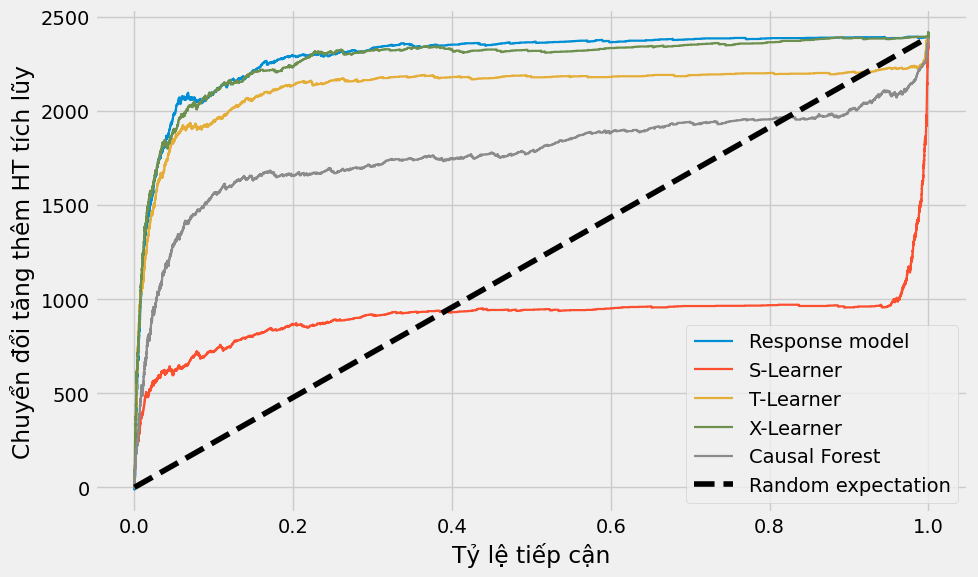

/tmp/ipykernel_2701/2966612412.py:8: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.axhline(0,color="black",ls="--",lw=1); plt.xlabel("Tỷ lệ tiếp cận"); plt.ylabel("Giá trị Qini tích lũy"); plt.legend(); plt.tight_layout(); plt.savefig(FIGURES/"qini_curves.png",dpi=160); plt.show()


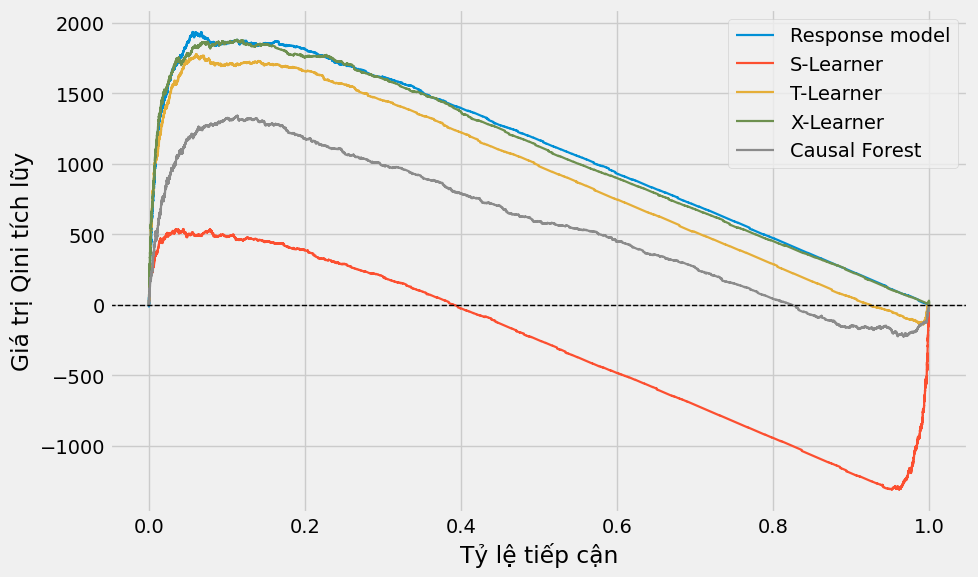

In [14]:
curves={name:curve_metrics(Yte,Tte,sc,TEST_TIE_BREAKER) for name,sc in test_scores.items()}
plt.figure(figsize=(10,6))
for name,c in curves.items(): plt.plot(c["fraction"],c["gain"],label=name,lw=1.6)
anyc=next(iter(curves.values())); plt.plot(anyc["fraction"],anyc["random"],"k--",label="Random expectation")
plt.xlabel("Tỷ lệ tiếp cận"); plt.ylabel("Chuyển đổi tăng thêm HT tích lũy"); plt.legend(); plt.tight_layout(); plt.savefig(FIGURES/"uplift_curves.png",dpi=160); plt.show()
plt.figure(figsize=(10,6))
for name,c in curves.items(): plt.plot(c["fraction"],c["gain"]-c["random"],label=name,lw=1.6)
plt.axhline(0,color="black",ls="--",lw=1); plt.xlabel("Tỷ lệ tiếp cận"); plt.ylabel("Giá trị Qini tích lũy"); plt.legend(); plt.tight_layout(); plt.savefig(FIGURES/"qini_curves.png",dpi=160); plt.show()

## 18. Phân tích theo tỷ lệ tiếp cận

Ở mỗi tỷ lệ, chọn trực tiếp các điểm cao nhất và ước lượng chuyển đổi tăng thêm bằng HT. Random targeting được lặp 30 lần.

model,target_rate,Random targeting,Response model,X-Learner,abs_diff_vs_Response model,rel_diff_vs_Response model,abs_diff_vs_Random targeting,rel_diff_vs_Random targeting
0,0.05,114.810458,1988.627451,1900.392157,-8.823529e+01,-4.436995e-02,1.785582e+03,1.555243e+01
1,0.10,227.960784,2096.470588,2097.254902,7.843137e-01,3.741115e-04,1.869294e+03,8.200069e+00
2,0.20,472.575163,2289.803922,2233.725490,-5.607843e+01,-2.449049e-02,1.761150e+03,3.726709e+00
3,0.30,701.307190,2335.294118,2320.784314,-1.450980e+01,-6.213266e-03,1.619477e+03,2.309226e+00
4,0.40,955.124183,2352.156863,2327.843137,-2.431373e+01,-1.033678e-02,1.372719e+03,1.437215e+00
5,0.50,1196.457516,2364.313725,2318.823529,-4.549020e+01,-1.924034e-02,1.122366e+03,9.380743e-01
6,0.75,1787.098039,2385.098039,2349.411765,-3.568627e+01,-1.496218e-02,5.623137e+02,3.146519e-01
7,1.00,2390.980392,2390.980392,2390.980392,-9.094947e-13,-3.803857e-16,-6.366463e-12,-2.662700e-15


,model,target_rate,selected_n,incremental_conversions,ci_low_95,ci_high_95,bootstrap_std,bootstrap_repeats,n_treated,n_control,conversions_treated,conversions_control
0,Response model,0.1,209578,2096.470588,1742.666667,2429.823529,176.050905,1000,180848,28730,4927,555
1,Response model,0.2,419155,2289.803922,1908.156863,2627.313725,182.509149,1000,359420,59735,5267,586
2,Response model,0.5,1047886,2364.313725,2007.588235,2718.901961,180.380849,1000,892349,155537,5472,611
3,S-Learner,0.1,209578,721.176471,536.068627,899.607843,92.485037,1000,179732,29846,1514,159
4,S-Learner,0.2,419155,864.705882,648.558824,1052.166667,105.065643,1000,357881,61274,1755,180
5,S-Learner,0.5,1047886,943.137255,720.764706,1141.725490,109.258672,1000,890946,156940,1952,203
6,T-Learner,0.1,209578,1945.098039,1641.127451,2245.500000,157.557240,1000,181292,28286,4141,439
7,T-Learner,0.2,419155,2135.686275,1802.323529,2445.549020,168.647437,1000,359566,59589,4473,469
8,T-Learner,0.5,1047886,2178.431373,1852.813725,2505.950980,170.200602,1000,892476,155410,4668,497
9,X-Learner,0.1,209578,2097.254902,1745.441176,2424.411765,171.070568,1000,180752,28826,4667,509


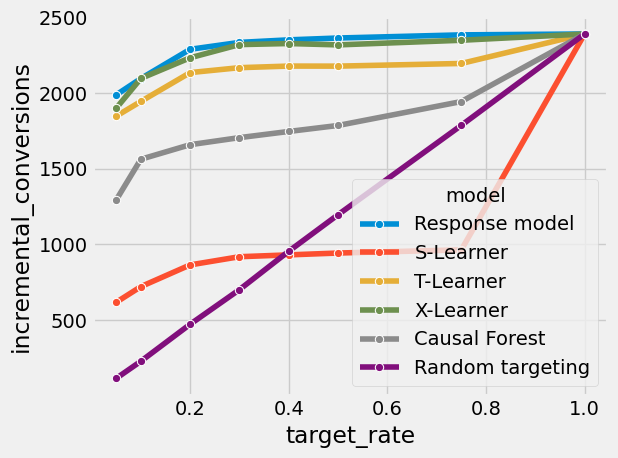

In [15]:
def gain_at_rates(y,t,score,tie_breaker,rates,e=PROPENSITY):
    order=rank_indices(score,tie_breaker); contrib=t*y/e-(1-t)*y/(1-e); out=[]
    for p in rates:
        k=max(1,int(np.ceil(p*len(y)))); out.append({"target_rate":p,"selected_n":k,"incremental_conversions":float(contrib[order[:k]].sum()),"policy_value_per_customer":float(contrib[order[:k]].sum()/len(y))})
    return out

def fixed_policy_bootstrap_ci(y,t,score,tie_breaker,rates,e=PROPENSITY,n_boot=BOOTSTRAP_REPEATS,seed=RANDOM_STATE):
    # Khoảng tin cậy có điều kiện theo chính sách xếp hạng đã cố định.
    # Lấy mẫu lặp lại phân tầng theo treatment; với Y nhị phân, số chuyển đổi lặp lại tuân theo phân phối nhị thức.
    order=rank_indices(score,tie_breaker); rng=np.random.default_rng(seed); rows=[]
    for p in rates:
        k=max(1,int(np.ceil(p*len(y)))); idx=order[:k]; yy=np.asarray(y)[idx]; tt=np.asarray(t)[idx]
        nt=int(tt.sum()); nc=int(len(tt)-nt); yt=int(yy[tt==1].sum()); yc=int(yy[tt==0].sum())
        if nt==0 or nc==0: raise ValueError(f"Thiếu nhóm treatment hoặc control tại tỷ lệ {p:.0%}.")
        sim=rng.binomial(nt,yt/nt,size=n_boot)/e-rng.binomial(nc,yc/nc,size=n_boot)/(1-e)
        rows.append({"target_rate":p,"selected_n":k,"incremental_conversions":float(yt/e-yc/(1-e)),"ci_low_95":float(np.quantile(sim,.025)),"ci_high_95":float(np.quantile(sim,.975)),"bootstrap_std":float(np.std(sim,ddof=1)),"bootstrap_repeats":n_boot,"n_treated":nt,"n_control":nc,"conversions_treated":yt,"conversions_control":yc})
    return rows
policy=[]
for name,sc in test_scores.items():
    for r in gain_at_rates(Yte,Tte,sc,TEST_TIE_BREAKER,TARGET_RATES): policy.append({"model":name,**r})
policy_ci=[]
for j,(name,sc) in enumerate(test_scores.items()):
    for r in fixed_policy_bootstrap_ci(Yte,Tte,sc,TEST_TIE_BREAKER,CI_TARGET_RATES,seed=RANDOM_STATE+1_000+j): policy_ci.append({"model":name,**r})
targeting_policy_ci=pd.DataFrame(policy_ci)
rng=np.random.default_rng(RANDOM_STATE+900); random_rows=[]
for rep in range(RANDOM_REPEATS):
    sc=rng.random(len(Yte),dtype=np.float32)
    for r in gain_at_rates(Yte,Tte,sc,TEST_TIE_BREAKER,TARGET_RATES): random_rows.append({"repeat":rep,**r})
random_targeting_results=pd.DataFrame(random_rows)
rand_agg=random_targeting_results.groupby("target_rate").agg(selected_n=("selected_n","first"),incremental_conversions=("incremental_conversions","mean"),incremental_conversions_std=("incremental_conversions","std"),policy_value_per_customer=("policy_value_per_customer","mean")).reset_index()
for _,r in rand_agg.iterrows(): policy.append({"model":"Random targeting",**r.to_dict()})
targeting_policy_results=pd.DataFrame(policy).merge(targeting_policy_ci[["model","target_rate","ci_low_95","ci_high_95","bootstrap_std","bootstrap_repeats"]],on=["model","target_rate"],how="left")
uplift_names=[n for n in ["S-Learner","T-Learner","X-Learner","Causal Forest"] if n in test_scores]
best_uplift=test_metrics[test_metrics.model.isin(uplift_names)].iloc[0].model
base=targeting_policy_results[targeting_policy_results.model.isin([best_uplift,"Response model","Random targeting"])].pivot(index="target_rate",columns="model",values="incremental_conversions")
for b in ["Response model","Random targeting"]:
    if b in base: base[f"abs_diff_vs_{b}"]=base[best_uplift]-base[b]; base[f"rel_diff_vs_{b}"]=base[f"abs_diff_vs_{b}"]/base[b].abs().replace(0,np.nan)
comparison=base.reset_index(); targeting_policy_results=targeting_policy_results.merge(comparison,on="target_rate",how="left")
targeting_policy_results.to_csv(TABLES/"targeting_policy_results.csv",index=False); targeting_policy_ci.to_csv(TABLES/"targeting_policy_ci.csv",index=False); random_targeting_results.to_csv(TABLES/"random_targeting_results.csv",index=False)
display(comparison); display(targeting_policy_ci)
sns.lineplot(data=targeting_policy_results,x="target_rate",y="incremental_conversions",hue="model",marker="o"); plt.tight_layout(); plt.savefig(FIGURES/"incremental_conversions_by_target_rate.png",dpi=160); plt.show()

## 19. Phân tích theo nhóm phân vị

Chia mỗi mô hình uplift thành 10 nhóm xếp hạng cao xuống thấp và báo cáo uplift quan sát có điều chỉnh cùng gain HT.

,model,decile,n,mean_predicted_uplift,n_treated,n_control,conversion_treated,conversion_control,adjusted_observed_uplift,incremental_conversions
0,Response model,1,209578,0.031290,180848,28730,0.027244,0.019318,0.010003,2096.470588
1,Response model,2,209577,0.001885,178572,31005,0.001904,0.001000,0.000922,193.333333
2,Response model,3,209577,0.000683,177620,31957,0.000664,0.000438,0.000217,45.490196
3,Response model,4,209577,0.000333,177412,32165,0.000304,0.000218,0.000080,16.862745
4,Response model,5,209577,0.000189,177897,31680,0.000186,0.000126,0.000058,12.156863
5,Response model,6,209577,0.000125,177730,31847,0.000129,0.000126,0.000002,0.392157
6,Response model,7,209577,0.000084,177975,31602,0.000107,0.000032,0.000075,15.686275
7,Response model,8,209577,0.000078,178179,31398,0.000056,0.000032,0.000024,5.098039
8,Response model,9,209577,0.000077,177956,31621,0.000022,0.000000,0.000022,4.705882
9,Response model,10,209577,0.000076,177774,31803,0.000068,0.000063,0.000004,0.784314


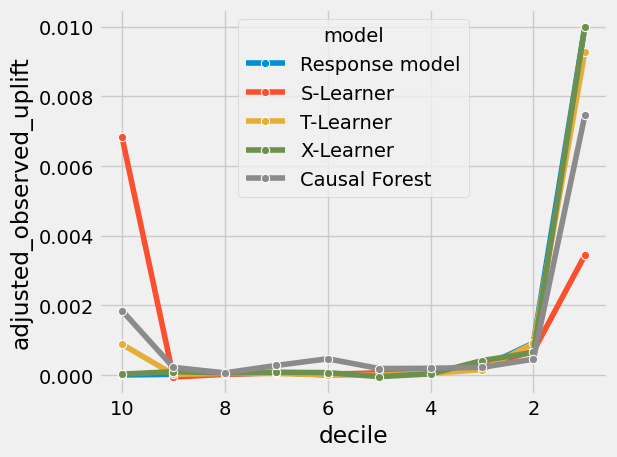

group,decile_1,decile_10,decile_2,decile_3,decile_4,decile_5,decile_6,decile_7,decile_8,decile_9,top_10%,top_20%,top_50%
model,,,,,,,,,,,,,
Causal Forest,0.855247,0.853739,0.849492,0.849172,0.849354,0.848848,0.848972,0.849607,0.849048,0.849182,0.855247,0.852370,0.850423
Response model,0.862915,0.848251,0.852059,0.847517,0.846524,0.848838,0.848042,0.849211,0.850184,0.849120,0.862915,0.857487,0.851571
S-Learner,0.857590,0.855285,0.850041,0.846968,0.847569,0.848991,0.848982,0.849273,0.849974,0.847989,0.857590,0.853815,0.850232
T-Learner,0.865034,0.848638,0.850637,0.847106,0.848084,0.847598,0.848919,0.848185,0.848991,0.849468,0.865034,0.857835,0.851692
X-Learner,0.862457,0.847483,0.853920,0.849072,0.847770,0.847817,0.849029,0.848418,0.847922,0.848772,0.862457,0.858188,0.852207


Nhóm có 0 treatment/control: 0


In [16]:
def deciles(name,score,tie_breaker):
    order=rank_indices(score,tie_breaker); groups=np.empty(len(score),dtype=np.int8); groups[order]=np.minimum(9,np.arange(len(score))*10//len(score))+1
    rows=[]
    for d in range(1,11):
        m=groups==d; yy=Yte[m]; tt=Tte[m]; nt=tt.sum(); nc=len(tt)-nt; rt=yy[tt==1].mean() if nt else np.nan; rc=yy[tt==0].mean() if nc else np.nan
        ht=float((tt*yy/PROPENSITY-(1-tt)*yy/(1-PROPENSITY)).sum())
        rows.append({"model":name,"decile":d,"n":m.sum(),"mean_predicted_uplift":float(score[m].mean()),"n_treated":int(nt),"n_control":int(nc),"conversion_treated":rt,"conversion_control":rc,"adjusted_observed_uplift":ht/m.sum(),"incremental_conversions":ht})
    return rows
decile_results=pd.DataFrame([r for name in test_scores for r in deciles(name,test_scores[name],TEST_TIE_BREAKER)])
decile_results.to_csv(TABLES/"decile_results.csv",index=False); display(decile_results)
sns.lineplot(data=decile_results,x="decile",y="adjusted_observed_uplift",hue="model",marker="o"); plt.gca().invert_xaxis(); plt.tight_layout(); plt.savefig(FIGURES/"uplift_by_decile.png",dpi=160); plt.show()

# Kiểm tra cân bằng treatment cho mọi phân vị và các chính sách top-k lớn.
balance_rows=[]
for name,score in test_scores.items():
    order=rank_indices(score,TEST_TIE_BREAKER)
    for p in CI_TARGET_RATES:
        k=max(1,int(np.ceil(p*len(score)))); tt=Tte[order[:k]]; nt=int(tt.sum()); nc=int(k-nt)
        balance_rows.append({"model":name,"group_type":"top_k","group":f"top_{p:.0%}","target_rate":p,"decile":np.nan,"n":k,"n_treated":nt,"n_control":nc,"treatment_rate":nt/k})
for r in decile_results.itertuples(index=False):
    balance_rows.append({"model":r.model,"group_type":"decile","group":f"decile_{r.decile}","target_rate":np.nan,"decile":r.decile,"n":r.n,"n_treated":r.n_treated,"n_control":r.n_control,"treatment_rate":r.n_treated/r.n})
selection_balance_check=pd.DataFrame(balance_rows)
selection_balance_check["abs_deviation_from_0_85"]=(selection_balance_check.treatment_rate-PROPENSITY).abs()
selection_balance_check["within_0_01"]=selection_balance_check.abs_deviation_from_0_85.le(.01)
selection_balance_check.to_csv(TABLES/"selection_balance_check.csv",index=False)
assert selection_balance_check[["n_treated","n_control"]].gt(0).all().all(), "Có nhóm không có treatment hoặc control."
imbalanced=selection_balance_check.loc[~selection_balance_check.within_0_01]
if len(imbalanced): warnings_log.append(f"Có {len(imbalanced)} nhóm lớn lệch treatment rate quá 0.01 so với 0.85; xem selection_balance_check.csv.")
display(selection_balance_check.pivot(index="model",columns="group",values="treatment_rate"))
print("Nhóm có 0 treatment/control:", int(((selection_balance_check.n_treated==0)|(selection_balance_check.n_control==0)).sum()))

## 20. Độ quan trọng của đặc trưng

Chỉ trình bày đóng góp tương đối của đặc trưng ẩn danh. Thành phần nguồn được ghi rõ; không diễn giải nhân quả hay gán ý nghĩa nghiệp vụ.

In [17]:
fi=[]
def add_fi(model,component,obj):
    if hasattr(obj,"feature_importances_"):
        vals=np.asarray(obj.feature_importances_,float)[:12]; total=vals.sum()
        for f,v in zip(FEATURES,vals): fi.append({"model":model,"component":component,"feature":f,"importance":v,"relative_importance":v/total if total else np.nan})
if response is not None:add_fi("Response model","treated outcome model",response)
if s_model is not None:add_fi("S-Learner","single outcome model",s_model)
if t_model is not None:
    add_fi("T-Learner","mu1",t_model["mu1"]); add_fi("T-Learner","mu0",t_model["mu0"])
if x_model is not None:
    for c in ["mu1","mu0","tau1","tau0"]: add_fi("X-Learner",c,x_model[c])
if cf_model is not None:add_fi("Causal Forest","causal forest",cf_model)
feature_importance=pd.DataFrame(fi,columns=["model","component","feature","importance","relative_importance"])
if feature_importance.empty: feature_importance=pd.DataFrame([{"model":"N/A","component":"N/A","feature":"N/A","importance":np.nan,"relative_importance":np.nan,"reason":"Không có mô hình cung cấp feature_importances_."}])
feature_importance.to_csv(TABLES/"feature_importance.csv",index=False); display(feature_importance.head(20))

,model,component,feature,importance,relative_importance
0,Response model,treated outcome model,f0,149.0,0.070952
1,Response model,treated outcome model,f1,0.0,0.000000
2,Response model,treated outcome model,f2,403.0,0.191905
3,Response model,treated outcome model,f3,56.0,0.026667
4,Response model,treated outcome model,f4,228.0,0.108571
5,Response model,treated outcome model,f5,17.0,0.008095
6,Response model,treated outcome model,f6,227.0,0.108095
7,Response model,treated outcome model,f7,85.0,0.040476
8,Response model,treated outcome model,f8,306.0,0.145714
9,Response model,treated outcome model,f9,195.0,0.092857


## 21. Kiểm tra độ tin cậy của kết quả

Kiểm tra file, kích thước dự báo, dữ liệu thiếu, rò rỉ, tính đơn điệu của trục đường cong và trạng thái mô hình. Bootstrap không dùng để thay đổi lựa chọn mô hình.

In [18]:
training_log_df=pd.DataFrame(training_log); training_log_df.to_csv(TABLES/"training_log.csv",index=False)
assert set(FEATURES).isdisjoint({"treatment","conversion","visit","exposure"})
for name,c in curves.items(): assert np.all(np.diff(c["fraction"])>=0) and len(c["gain"])==len(test_df)+1
required_csv=["environment_versions.csv","split_summary.csv","training_sample_summary.csv","model_parameters.csv","training_log.csv","validation_metrics.csv","test_metrics.csv","uplift_score_summary.csv","targeting_policy_results.csv","targeting_policy_ci.csv","decile_results.csv","feature_importance.csv","random_targeting_results.csv"]
for f in required_csv:
    p=TABLES/f; assert p.exists() and p.stat().st_size>0, f"Thiếu/rỗng: {p}"
if not CF_HONESTY_SUPPORTED:
    warnings_log.append(
        f"CausalML {metadata.version('causalml')}: phiên bản đang dùng không hỗ trợ ước lượng trung thực (honesty)."
    )
else:
    warnings_log.append("Rừng nhân quả chạy với honesty=False để giữ phương pháp đã khóa.")
warnings_log.append(
    f"Rừng nhân quả dùng n_jobs={cf_model.get_params(deep=False)['n_jobs']}; "
    f"huấn luyện trên {TRAIN_USAGE['causal_forest']['training_n']:,} quan sát."
)
if TRAIN_USAGE["causal_forest"]["training_n"] < len(train_df):
    warnings_log.append("Rừng nhân quả sử dụng mẫu con phân tầng, khác quy mô huấn luyện của các mô hình hiệu ứng tăng thêm còn lại.")
assert TRAIN_USAGE["s_learner"]["training_n"] == len(train_df)
if CF_TRAIN_MAX is None:
    assert TRAIN_USAGE["causal_forest"]["training_n"] == len(train_df)
pd.DataFrame({"warning":warnings_log or ["Không có cảnh báo bổ sung."]}).to_csv(TABLES/"errors_or_warnings.csv",index=False)
print("Kiểm tra độ tin cậy đạt yêu cầu. Số cảnh báo:",len(warnings_log))

Kiểm tra độ tin cậy đạt yêu cầu. Số cảnh báo: 4


## 22. Tóm tắt kết quả dùng cho khóa luận

Tạo báo cáo tiếng Việt chỉ từ số liệu thực tế đã chạy, kèm cấu hình, kết quả, nhận xét, giới hạn và danh sách đầu ra.

In [19]:
RUN_ENDED=datetime.now(timezone.utc); elapsed=(RUN_ENDED-RUN_STARTED).total_seconds()
run_config={**fingerprint_payload,"fingerprint":FINGERPRINT,"data_path":str(DATA_PATH),"original_n":global_agg["n"],"split_n":{k:v["n"] for k,v in agg.items()},"actual_n":{"train":len(train_df),"validation":len(valid_df),"test":len(test_df)},"treatment_assignment_probability":PROPENSITY,"tie_break_seed":TIE_BREAK_SEED,"tie_break_rule":"SplitMix64(row_id + seed), lexsort by descending score then tie-break value","started_utc":RUN_STARTED.isoformat(),"ended_utc":RUN_ENDED.isoformat(),"elapsed_seconds":elapsed}
(OUT/"run_config.json").write_text(json.dumps(run_config,ensure_ascii=False,indent=2,default=str),encoding="utf-8")
best_auuc=test_metrics.sort_values("auuc",ascending=False).iloc[0].model; best_qini=test_metrics.iloc[0].model
findings=[]
findings.append(f"Mô hình có AUUC cao nhất trên test là {best_auuc}.")
findings.append(f"Mô hình có Qini cao nhất trên test là {best_qini}.")
for p in [0.1,0.2,0.5]:
    sub=targeting_policy_results[targeting_policy_results.target_rate.eq(p)].sort_values("incremental_conversions",ascending=False).iloc[0]
    findings.append(f"Tại tỷ lệ tiếp cận {p:.0%}, {sub.model} đạt ước lượng {sub.incremental_conversions:,.1f} chuyển đổi tăng thêm trên tập đánh giá.")
files=sorted(str(p.relative_to(ROOT)).replace("\\","/") for p in OUT.rglob("*") if p.is_file())
def mdt(df):
    # Tạo bảng Markdown không phụ thuộc gói tùy chọn `tabulate`.
    d=df.copy()
    for c in d.columns:
        d[c]=d[c].map(lambda x: "" if pd.isna(x) else (f"{x:.6g}" if isinstance(x,(float,np.floating)) else str(x).replace("|","\\|")))
    header="| " + " | ".join(map(str,d.columns)) + " |"
    rule="| " + " | ".join(["---"]*len(d.columns)) + " |"
    rows=["| " + " | ".join(map(str,row)) + " |" for row in d.itertuples(index=False,name=None)]
    return "\n".join([header,rule,*rows])
summary=f"""# Tóm tắt kết quả thực nghiệm Uplift\n\n- Thời gian chạy UTC: {RUN_STARTED.isoformat()} – {RUN_ENDED.isoformat()} ({elapsed/60:.2f} phút)\n- Chế độ: `{RUN_MODE}`; seed: {RANDOM_STATE}\n- Dữ liệu gốc: {global_agg['n']:,} quan sát; train/validation/test logic: {agg['train']['n']:,}/{agg['validation']['n']:,}/{agg['test']['n']:,}\n- Mẫu thực tế: train {len(train_df):,}; validation {len(valid_df):,}; test {len(test_df):,}\n- Thuật toán cơ sở: LightGBM; Causal Forest: causalml CausalRandomForestRegressor\n- Xác suất phân bổ vào nhóm treatment theo thiết kế: {PROPENSITY:.6f}\n\n## Phiên bản thư viện\n\n{mdt(env_df)}\n\n## Siêu tham số và ứng viên\n\n{mdt(model_parameters)}\n\n## Kết quả validation\n\n{mdt(validation_metrics)}\n\n## Kết quả test\n\n{mdt(test_metrics)}\n\n## Kết quả theo tỷ lệ tiếp cận\n\n{mdt(targeting_policy_results[['model','target_rate','selected_n','incremental_conversions','policy_value_per_customer','ci_low_95','ci_high_95']])}\n\n## Khoảng tin cậy 95% của chính sách cố định\n\nKhoảng tin cậy được tính bằng lấy mẫu lặp lại phân tầng theo nhóm treatment trên tập kiểm tra, có điều kiện theo thứ hạng điểm của từng mô hình.\n\n{mdt(targeting_policy_ci)}\n\n## Kết luận theo chỉ số\n\n- AUUC cao nhất: **{best_auuc}**.\n- Qini cao nhất: **{best_qini}**.\n\n## Nhận xét dựa trên kết quả thực tế\n\n""" + "\n".join(f"{i+1}. {x}" for i,x in enumerate(findings)) + """\n\nKhông diễn giải ý nghĩa nghiệp vụ của f0–f11 và không xem feature importance là bằng chứng nhân quả.\n\n## Cảnh báo và giới hạn\n\n""" + "\n".join(f"- {x}" for x in (warnings_log or ["Không có cảnh báo bổ sung."])) + "\n\n## Tệp đầu ra\n\n" + "\n".join(f"- `{x}`" for x in files)
summary=summary.replace(f"- Xác suất phân bổ vào nhóm treatment theo thiết kế: {PROPENSITY:.6f}",f"- Xác suất phân bổ vào nhóm treatment theo thiết kế: {PROPENSITY:.6f}\n- Điểm hòa được phá bằng SplitMix64 từ `row_id` và seed {TIE_BREAK_SEED}, có thể tái lập và độc lập với treatment/outcome; quy tắc chỉ đổi thứ tự giữa các score bằng nhau.")
summary=summary.replace("## Kết luận theo chỉ số","Không suy luận mô hình nào vượt trội về mặt thống kê chỉ từ việc các khoảng tin cậy riêng lẻ chồng lấp hoặc không chồng lấp; cần khoảng tin cậy cho chênh lệch ghép cặp hoặc kiểm định trực tiếp.\n\n## Kiểm tra cân bằng lựa chọn\n\nBảng đầy đủ được lưu tại `outputs/tables/selection_balance_check.csv`.\n\n"+mdt(selection_balance_check)+"\n\n## Kết luận theo chỉ số")
summary += "\n\n## Chi tiết số quan sát và thời gian theo mô hình\n\n" + mdt(training_log_df)
(OUT/"modeling_results_summary.md").write_text(summary,encoding="utf-8")
print(f"HOÀN TẤT trong {elapsed/60:.2f} phút | best AUUC={best_auuc} | best Qini={best_qini}")
display(test_metrics)
summary = summary.replace(
    "`outputs/tables/selection_balance_check.csv`",
    f"`{TABLES.relative_to(ROOT).as_posix()}/selection_balance_check.csv`"
)
summary = summary.replace(
    "## Siêu tham số và ứng viên",
    "## Siêu tham số và ứng viên\n\n"
    "Các ứng viên S-Learner đều được huấn luyện trên toàn bộ tập huấn luyện. "
    "Ứng viên được chọn được giữ nguyên để đánh giá cuối cùng, không huấn luyện lại. "
    "Điểm xác thực của ứng viên được chọn phải khớp bảng kết quả xác thực."
)
summary = summary.replace(
    "## Chi tiết số quan sát và thời gian theo mô hình",
    "## Chi tiết số quan sát và thời gian theo mô hình\n\n"
    "Thời gian của S-Learner là thời gian học của ứng viên được chọn; "
    "thời gian học của từng ứng viên được ghi riêng trong bảng siêu tham số. "
    f"Rừng nhân quả thực tế học trên {TRAIN_USAGE['causal_forest']['training_n']:,} quan sát."
)
(OUT / "modeling_results_summary.md").write_text(summary, encoding="utf-8")

HOÀN TẤT trong 14.72 phút | best AUUC=Response model | best Qini=Response model


,model,auuc,qini,total_incremental_conversions,n
0,Response model,2289.110231,1093.620035,2390.980392,2095771
3,X-Learner,2267.427688,1071.937492,2390.980392,2095771
2,T-Learner,2121.319284,925.829088,2390.980392,2095771
4,Causal Forest,1774.355111,578.864915,2390.980392,2095771
1,S-Learner,909.011651,-286.478545,2390.980392,2095771


20451